# **04 - Epidemiology and ML Modeling**

Este notebook carrega os artefatos processados do pipeline genômico e realiza a etapa de análise exploratória e aprendizado não supervisionado.

Os objetivos principais são:

1. caracterizar o perfil epidemiológico das amostras;
2. investigar a estrutura genética do conjunto por redução de dimensionalidade e clusterização;
3. comparar os agrupamentos obtidos com os clados formais conhecidos;
4. Recuperar os agrupamentos naturais por modelos supervisionados;
5. gerar artefatos e visualizações que servirão de base para as próximas etapas do pipeline.

Nesta versão, a análise geográfica não será incluída. O foco recai sobre:

- perfil epidemiológico por clado;
- PCA;
- clusterização hierárquica;
- métodos complementares de agrupamento.

## **4.1 Imports**

In [1]:
from pathlib import Path

import numpy as np
import re
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from clade_clustering.paths import PROCESSED_DIR, RESULTS_DIR

from sklearn.decomposition import PCA

from clade_clustering.scripts.pca_helpers.plots import (
    plot_cumulative_variance,
    plot_explained_variance_ratio,
    plot_pca_scatter,
)

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

from clade_clustering.scripts.clustering_helpers.plots import (
    plot_inertia_silhouette_vs_k,
    plot_clusters_pca,
)
from clade_clustering.scripts.clustering_helpers.metrics import silhouette_by_cluster

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report


SEED = 42

In [2]:
DATA_VERSION = "v4"

RESULTS_VERSION_DIR = RESULTS_DIR / DATA_VERSION
MATRICES_DIR = RESULTS_VERSION_DIR / "matrices" / "parsnp"

X_GENOTYPES_PATH = MATRICES_DIR / "X_genotypes.parquet"
SNP_INFO_PATH = MATRICES_DIR / "snp_info.parquet"
SAMPLE_METADATA_PATH = MATRICES_DIR / "sample_metadata.parquet"

CLUSTERING_DIR = RESULTS_VERSION_DIR / "clustering"
CLUSTERING_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_METADATA_LABELED_PATH = MATRICES_DIR / "sample_metadata_labeled.parquet"
EXPERT_CLADE_LABELS_PATH = CLUSTERING_DIR / "expert_clade_labels.parquet"


# Será produzido neste notebook após tratar loci multialélicos
X_ENCODED_PATH = MATRICES_DIR / "X_encoded.parquet"

# Amostras Ca e SRR, excluídas do ajuste da PCA e dos agrupamentos
X_ENCODED_HOLDOUT_PATH = MATRICES_DIR / "X_encoded_holdout.parquet"
SAMPLE_METADATA_HOLDOUT_PATH = MATRICES_DIR / "sample_metadata_holdout.parquet"

In [3]:
required_inputs = {
    "X_genotypes": X_GENOTYPES_PATH,
    "snp_info": SNP_INFO_PATH,
    "sample_metadata": SAMPLE_METADATA_PATH,
}

missing_inputs = [
    (name, path)
    for name, path in required_inputs.items()
    if not path.exists()
]

if missing_inputs:
    details = "\n".join(
        f"- {name}: {path}"
        for name, path in missing_inputs
    )
    raise FileNotFoundError(
        f"Entradas necessárias não encontradas:\n{details}"
    )

print("Entradas validadas:")
for name, path in required_inputs.items():
    print(f"{name:16s}: {path}")

Entradas validadas:
X_genotypes     : /home/lucas/workspace/projects/clade-clustering/data/results/v4/matrices/parsnp/X_genotypes.parquet
snp_info        : /home/lucas/workspace/projects/clade-clustering/data/results/v4/matrices/parsnp/snp_info.parquet
sample_metadata : /home/lucas/workspace/projects/clade-clustering/data/results/v4/matrices/parsnp/sample_metadata.parquet


## **4.2 Load data artifacts**

In [4]:
X_genotypes = pd.read_parquet(X_GENOTYPES_PATH)
snp_info = pd.read_parquet(SNP_INFO_PATH)
sample_metadata = pd.read_parquet(SAMPLE_METADATA_PATH)

print("X_genotypes:", X_genotypes.shape)
print("snp_info:", snp_info.shape)
print("sample_metadata:", sample_metadata.shape)

X_genotypes: (1254, 97034)
snp_info: (97034, 8)
sample_metadata: (1254, 24)


In [5]:
if X_genotypes.shape[0] != sample_metadata.shape[0]:
    raise RuntimeError(
        "Número de amostras de X_genotypes e sample_metadata não coincide."
    )

if X_genotypes.shape[1] != snp_info.shape[0]:
    raise RuntimeError(
        "Número de loci de X_genotypes e snp_info não coincide."
    )

if not X_genotypes.index.equals(sample_metadata.index):
    raise RuntimeError(
        "Os índices de X_genotypes e sample_metadata não estão alinhados."
    )

if not X_genotypes.index.is_unique:
    raise RuntimeError("X_genotypes possui amostras duplicadas.")

if not X_genotypes.columns.is_unique:
    raise RuntimeError("X_genotypes possui loci duplicados.")

print("Estrutura dos artefatos validada.")

Estrutura dos artefatos validada.


## **4.3 Prepare the matrix of genotypes**

A matriz `X_genotypes`, construída a partir do VCF do Parsnp, representa
os alelos identificados em cada locus por códigos inteiros:

- `0`: alelo de referência (REF);
- `1`: primeiro alelo alternativo (ALT1);
- `2`: segundo alelo alternativo (ALT2);
- e assim sucessivamente.

Para loci bialélicos, essa representação binária pode ser utilizada
diretamente nos métodos de Machine Learning.

Entretanto, em loci multialélicos, códigos como `0`, `1` e `2`
representam categorias distintas, sem relação ordinal entre si.
A utilização direta desses códigos em métodos baseados em distâncias
introduziria diferenças numéricas artificiais entre os alelos.

### **4.3.1 Loci characterization and missing values**

In [6]:
n_biallelic = (~snp_info["alt"].astype(str).str.contains(",")).sum()
n_multiallelic = snp_info["alt"].astype(str).str.contains(",").sum()

n_missing = int(X_genotypes.isna().sum().sum())

print(f"Loci bialélicos:     {n_biallelic:,}")
print(f"Loci multialélicos: {n_multiallelic:,}")
print(f"Total:               {len(snp_info):,}")
print(f"Valores ausentes:     {n_missing:,}")

if n_missing:
    raise RuntimeError(
        "X_genotypes contém valores ausentes. "
        "É necessário definir o tratamento antes da codificação."
    )

print("\nCódigos alélicos observados:")
print(np.unique(X_genotypes.to_numpy()))

Loci bialélicos:     89,933
Loci multialélicos: 7,101
Total:               97,034
Valores ausentes:     0

Códigos alélicos observados:
[0 1 2 3 4]


### **4.3.2 Encode multiallelic loci**

In [7]:
def encode_genotypes(X_df):
    """
    Bialélicos (0/1): mantém a coluna original.

    Multialélicos (0/1/2/...): expande em colunas binárias por alelo,
    incluindo o alelo de referência (código 0).

    Nomes: chrom:pos_ALELO (ex.: CP043534.1:941787_G).

    Normaliza REF/ALT para maiúsculas.
    Colisões de nomes são combinadas por OR lógico.
    """
    pat = re.compile(r"^(.+):(\d+):([A-Za-z]+)>(.+)$")

    new_cols = {}
    n_bi = n_multi = n_collisions = 0

    for col in X_df.columns:
        match = pat.match(col)

        if match is None:
            raise RuntimeError(f"Identificador de SNP inválido: {col}")

        chrom, pos, ref, alts_str = match.groups()
        alts = alts_str.split(",")

        values = X_df[col].to_numpy()

        if not np.all(values == np.rint(values)):
            raise RuntimeError(f"Códigos não inteiros no locus: {col}")

        if values.min() < 0 or values.max() > len(alts):
            raise RuntimeError(
                f"Códigos fora do intervalo esperado no locus: {col}"
            )

        codes = values.astype(np.int8, copy=False)

        if len(alts) == 1:
            n_bi += 1
            new_cols[col] = codes
            continue

        n_multi += 1

        alleles = [ref.upper()] + [alt.upper() for alt in alts]

        for code, allele in enumerate(alleles):
            key = f"{chrom}:{pos}_{allele}"
            col_bin = (codes == code).astype(np.int8)

            if key in new_cols:
                n_collisions += 1
                new_cols[key] = np.maximum(new_cols[key], col_bin)
            else:
                new_cols[key] = col_bin

    result = pd.DataFrame(new_cols, index=X_df.index)

    print(f"Bialélicos mantidos:      {n_bi:,}")
    print(f"Multialélicos expandidos: {n_multi:,}")
    print(f"Colisões de nomes:        {n_collisions:,}")
    print(f"X_genotypes: {X_df.shape}")
    print(f"X_encoded:   {result.shape}")

    return result

In [8]:
X_encoded = encode_genotypes(X_genotypes)

Bialélicos mantidos:      89,933
Multialélicos expandidos: 7,101
Colisões de nomes:        6,006
X_genotypes: (1254, 97034)
X_encoded:   (1254, 105317)


- **Separação das amostras hold-out**

As 6 amostras Ca (Ca9–Ca14) e as 5 SRR não são genomas do NCBI. Elas são separadas aqui, antes da PCA, para que PCA, clustering hierárquico e KMeans sejam ajustados apenas com os 1.243 genomas restantes. Na seção 4.7, os hold-outs são projetados no espaço da PCA e classificados pelo KMeans já ajustado.

Os artefatos do notebook 03 em disco não são alterados: a filtragem de `X_genotypes` e `sample_metadata` vale só em memória.

In [9]:
holdout_mask = sample_metadata["vcf_sample"].str.startswith(("Ca", "SRR"), na=False)

n_ca = int(sample_metadata["vcf_sample"].str.startswith("Ca", na=False).sum())
n_srr = int(sample_metadata["vcf_sample"].str.startswith("SRR", na=False).sum())

if (n_ca, n_srr) != (6, 5):
    raise RuntimeError(
        f"Hold-outs inesperados: {n_ca} Ca e {n_srr} SRR (esperado: 6 Ca e 5 SRR)."
    )

holdout_index = sample_metadata.index[holdout_mask]
fit_index = sample_metadata.index[~holdout_mask]

X_encoded_holdout = X_encoded.loc[holdout_index].copy()
sample_metadata_holdout = sample_metadata.loc[holdout_index].copy()

X_encoded = X_encoded.loc[fit_index]
X_genotypes = X_genotypes.loc[fit_index]
sample_metadata = sample_metadata.loc[fit_index]

assert len(X_encoded_holdout) == 11
assert len(X_encoded) == 1243
assert X_encoded.index.equals(X_genotypes.index)
assert X_encoded.index.equals(sample_metadata.index)
assert X_encoded_holdout.columns.equals(X_encoded.columns)
assert not X_encoded.index.isin(holdout_index).any()

X_encoded_holdout.to_parquet(X_ENCODED_HOLDOUT_PATH)
sample_metadata_holdout.to_parquet(SAMPLE_METADATA_HOLDOUT_PATH)

print("Genomas para ajuste:", X_encoded.shape)
print("Hold-outs:          ", X_encoded_holdout.shape)
print(f"X_encoded_holdout salvo em:       {X_ENCODED_HOLDOUT_PATH}")
print(f"sample_metadata_holdout salvo em: {SAMPLE_METADATA_HOLDOUT_PATH}")

Genomas para ajuste: (1243, 105317)
Hold-outs:           (11, 105317)
X_encoded_holdout salvo em:       /home/lucas/workspace/projects/clade-clustering/data/results/v4/matrices/parsnp/X_encoded_holdout.parquet
sample_metadata_holdout salvo em: /home/lucas/workspace/projects/clade-clustering/data/results/v4/matrices/parsnp/sample_metadata_holdout.parquet


In [10]:
assert X_encoded.shape[0] == X_genotypes.shape[0]
assert X_encoded.index.equals(X_genotypes.index)
assert X_encoded.columns.is_unique

encoded_values = X_encoded.to_numpy(copy=False)

if not np.isin(encoded_values, [0, 1]).all():
    raise RuntimeError("X_encoded contém valores diferentes de 0 e 1.")

print("Matriz codificada validada.")
print("X_encoded:", X_encoded.shape)
print("Valores permitidos: 0 e 1")

Matriz codificada validada.
X_encoded: (1243, 105317)
Valores permitidos: 0 e 1


### **4.3.3 Look for constant features**

In [11]:
feature_min = encoded_values.min(axis=0)
feature_max = encoded_values.max(axis=0)

constant_mask = feature_min == feature_max

print(f"Features totais:    {X_encoded.shape[1]:,}")
print(f"Features constantes: {int(constant_mask.sum()):,}")
print(f"Features variáveis:  {int((~constant_mask).sum()):,}")

Features totais:    105,317
Features constantes: 67
Features variáveis:  105,250


### **4.3.4 Save the encoded matrix**

In [12]:
# Somente os 1.243 genomas usados no ajuste; os hold-outs ficam em X_encoded_holdout.parquet
assert len(X_encoded) == 1243
assert not X_encoded.index.isin(holdout_index).any()

X_encoded.to_parquet(X_ENCODED_PATH)

print(f"X_encoded salvo em: {X_ENCODED_PATH}")
print("X_encoded:", X_encoded.shape)

X_encoded salvo em: /home/lucas/workspace/projects/clade-clustering/data/results/v4/matrices/parsnp/X_encoded.parquet
X_encoded: (1243, 105317)


## **4.4 PCA**

Aplicamos PCA à matriz genotípica codificada (`X_encoded`) para
identificar as principais direções de variabilidade entre os genomas
de *Candida auris*.


Primeiro, analisamos a variância explicada pelos componentes
principais. 

### **4.4.1 Select the principal components**

In [13]:
# Matriz com multialélicos codificados
X = X_encoded.to_numpy(dtype=np.float32)

print("Dimensões da matriz:", X.shape)

Dimensões da matriz: (1243, 105317)


In [14]:
pca_full = PCA(
    n_components=50,
    svd_solver="randomized",
    random_state=SEED,
)

pca_full.fit(X)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",50
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'randomized'
,"random_state random_state: int, RandomState instance or None, default=NoneUsed when the 'arpack' or 'randomized' solvers are used. Pass an intfor reproducible results across multiple function calls.See :term:`Glossary <random_state>`... versionadded:: 0.18.0",42
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so a

(<Figure size 720x480 with 1 Axes>,
 <Axes: xlabel='Number of components', ylabel='Cumulative Explained Variance'>)

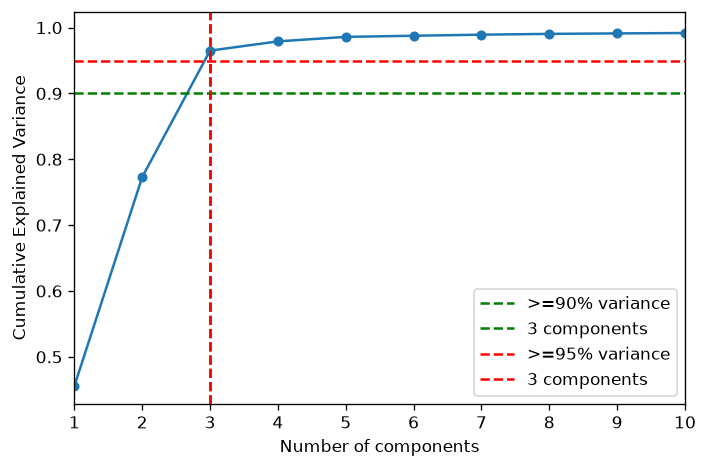

In [15]:
plot_cumulative_variance(pca=pca_full)

(<Figure size 720x480 with 1 Axes>,
 <Axes: xlabel='Principal Component', ylabel='Explained Variance Ratio'>)

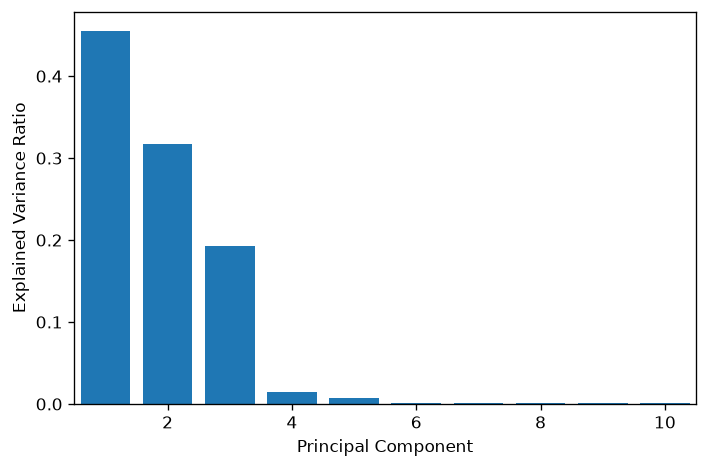

In [16]:
plot_explained_variance_ratio(
    pca=pca_full,
    n_components=10,
)

### **4.4.2 PCA on a fixed number of components**

In [17]:
pca = PCA(n_components=4, random_state=SEED)

Z = pca.fit_transform(X)

In [18]:
X_pca = pd.DataFrame(
    Z,
    columns=[f"PC{i+1}" for i in range(Z.shape[1])],
    index=X_encoded.index,
)

display(X_pca.head())

,PC1,PC2,PC3,PC4
accession,,,,
GCA_053222555.1,20.376038,6.862221,0.698159,0.053827
GCA_056555055.1,-40.084091,-44.270718,21.366508,0.159658
GCA_061480175.1,20.375349,6.861954,0.698058,0.053780
GCA_061086085.1,20.353411,6.851289,0.696350,0.056813
GCA_046250215.1,20.359230,6.847582,0.704823,0.053884


(<Figure size 1800x720 with 3 Axes>,
 array([<Axes: title={'center': 'PC1 vs PC2'}, xlabel='PC1', ylabel='PC2'>,
        <Axes: title={'center': 'PC1 vs PC3'}, xlabel='PC1', ylabel='PC3'>,
        <Axes: title={'center': 'PC1 vs PC4'}, xlabel='PC1', ylabel='PC4'>],
       dtype=object))

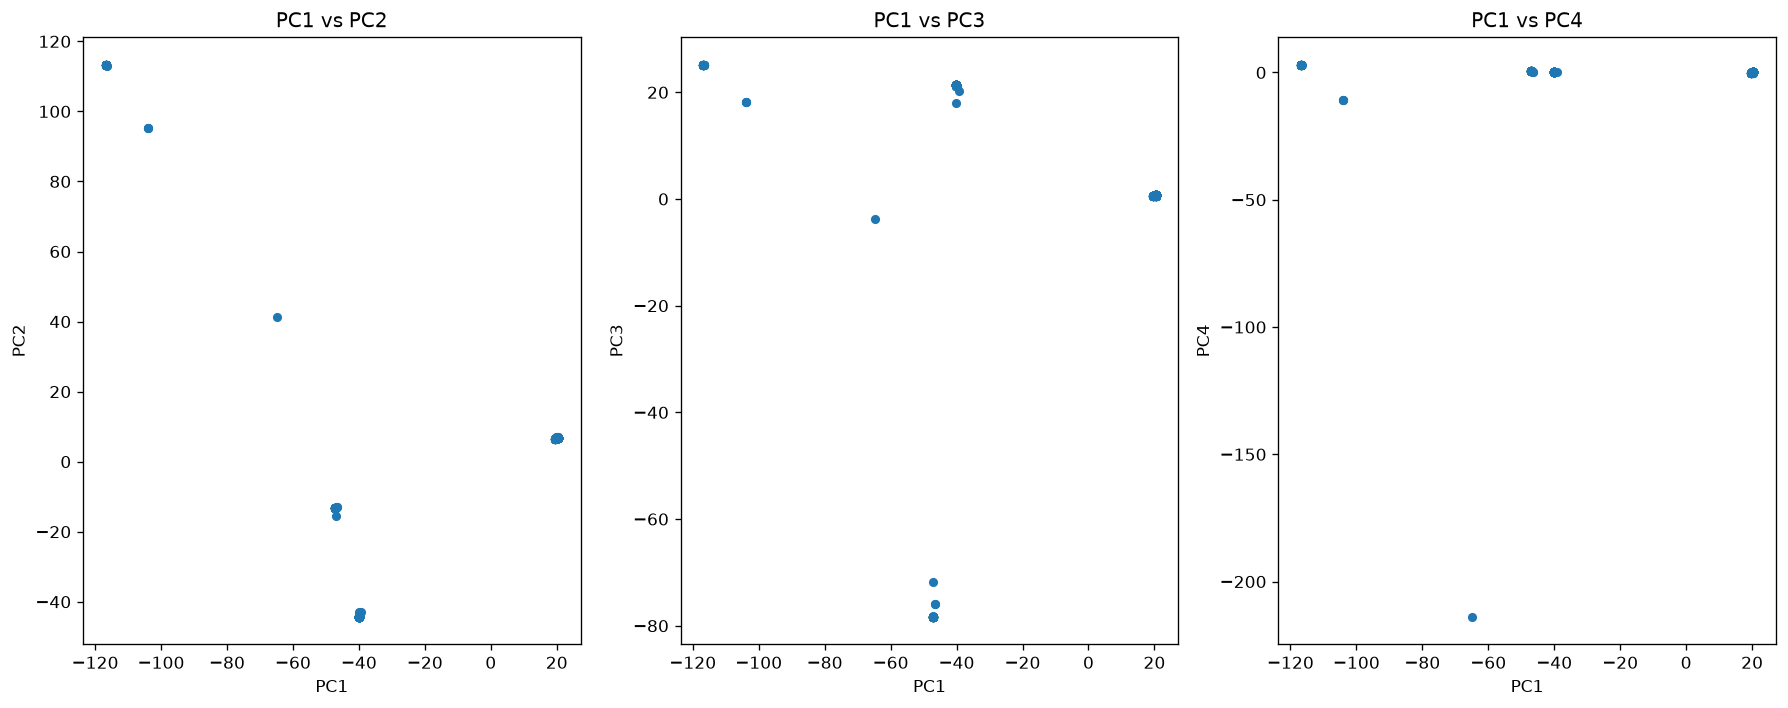

In [19]:
plot_pca_scatter(X_pca)

In [20]:
explained_variance = pd.DataFrame({
    "component": X_pca.columns,
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "cumulative_variance": np.cumsum(pca.explained_variance_ratio_),
})

display(explained_variance)

,component,explained_variance_ratio,cumulative_variance
0,PC1,0.455469,0.455469
1,PC2,0.317411,0.772880
2,PC3,0.192161,0.965040
3,PC4,0.014032,0.979072


In [21]:
pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=X_encoded.columns,
    columns=[f"PC{i}" for i in range(1, 5)],
)

PCA_LOADINGS_PATH = CLUSTERING_DIR / "pca_loadings.parquet"

pca_loadings.to_parquet(PCA_LOADINGS_PATH)

print(pca_loadings.shape)
print(PCA_LOADINGS_PATH)

(105317, 4)
/home/lucas/workspace/projects/clade-clustering/data/results/v4/clustering/pca_loadings.parquet


## **4.5 Hierarquical Clustering**

In [22]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z_hier = linkage(
    X_pca.to_numpy(),
    method="ward",
    metric="euclidean",
)

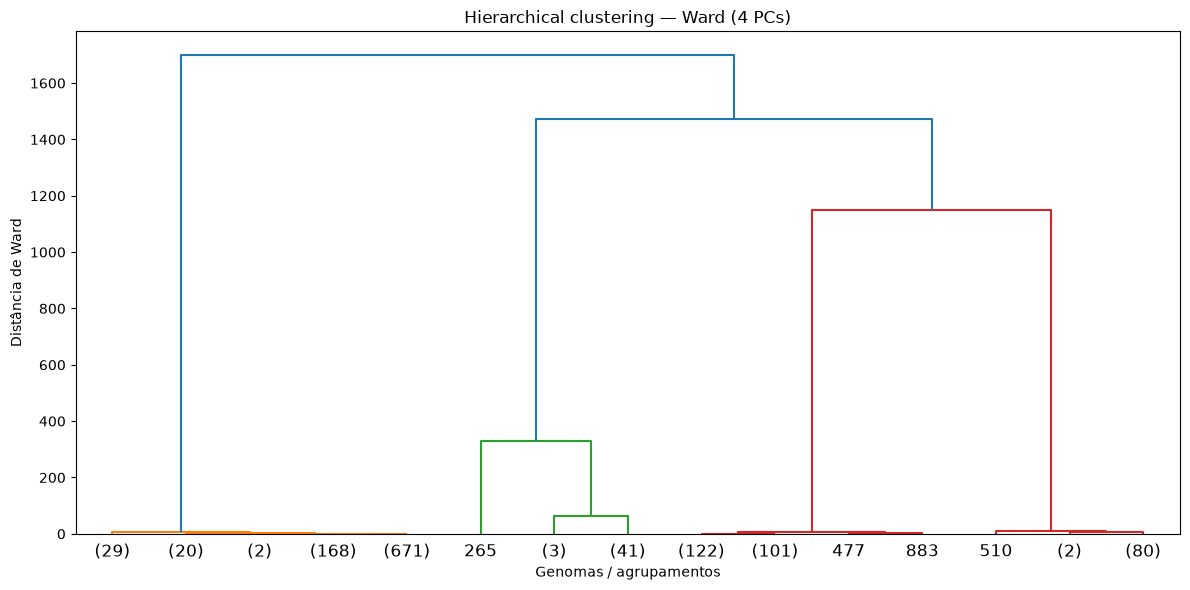

In [23]:
fig, ax = plt.subplots(figsize=(12, 6))

dendrogram(
    Z_hier,
    truncate_mode="lastp",
    p=15,
    show_leaf_counts=True,
    ax=ax,
)

ax.set(
    title="Hierarchical clustering — Ward (4 PCs)",
    xlabel="Genomas / agrupamentos",
    ylabel="Distância de Ward",
)

plt.tight_layout()
plt.show()

In [24]:
hier_clusters = pd.Series(
    fcluster(Z_hier, t=6, criterion="maxclust"),
    index=X_pca.index,
    name="hier_cluster",
)

print("Clusters identificados:")
display(hier_clusters.value_counts().sort_index())

Clusters identificados:


hier_cluster
1    890
2      3
3     41
4      1
5    225
6     83
Name: count, dtype: int64

## **4.6 KMeans clustering**

(<Figure size 700x400 with 2 Axes>,
 (<Axes: title={'center': 'Elbow (Inertia) + Silhouette vs k'}, xlabel='k', ylabel='Inertia'>,
  <Axes: ylabel='Silhouette score'>))

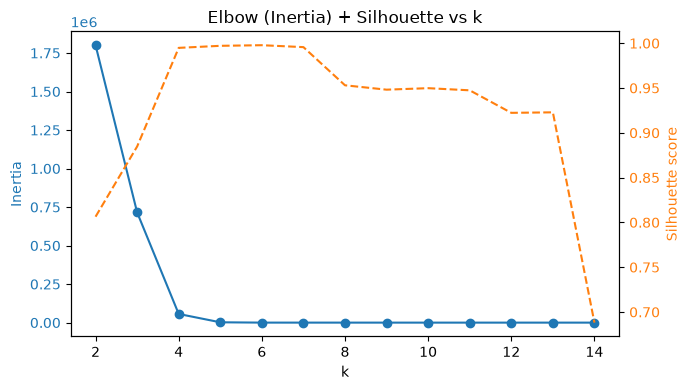

In [25]:
plot_inertia_silhouette_vs_k(Z)

In [26]:
km = KMeans(n_clusters=6, random_state=SEED, n_init=20)
cluster_labels = km.fit_predict(Z)

sample_metadata_df = sample_metadata.copy()
sample_metadata_df["cluster"] = cluster_labels

sil = silhouette_score(Z, cluster_labels)

print(f"Silhouette score: {sil:.4f}")
print(sample_metadata_df["cluster"].value_counts().sort_index())

Silhouette score: 0.9978
cluster
0    890
1    225
2     41
3     83
4      1
5      3
Name: count, dtype: int64


(<Figure size 600x500 with 1 Axes>,
 <Axes: title={'center': 'Cluster centroids in PCA space'}, xlabel='PC1', ylabel='PC2'>)

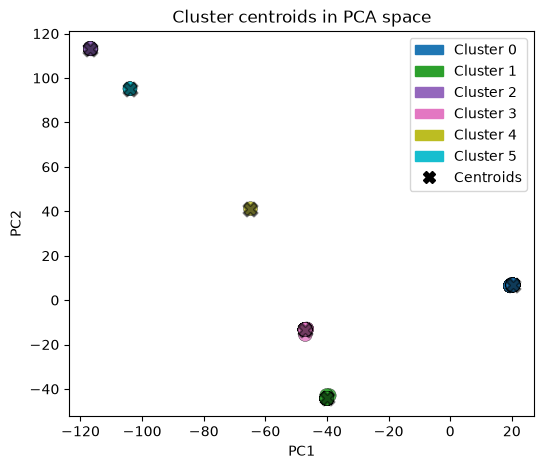

In [27]:
plot_clusters_pca(Z, cluster_labels)

In [28]:
comparison = pd.crosstab(
    sample_metadata_df["cluster"],
    hier_clusters,
    rownames=["KMeans"],
    colnames=["Hierárquico"],
)

display(comparison)

ari = adjusted_rand_score(
    sample_metadata_df["cluster"],
    hier_clusters,
)

print(f"Adjusted Rand Index: {ari:.4f}")

Hierárquico,1,2,3,4,5,6
KMeans,,,,,,
0,890,0,0,0,0,0
1,0,0,0,0,225,0
2,0,0,41,0,0,0
3,0,0,0,0,0,83
4,0,0,0,1,0,0
5,0,3,0,0,0,0


Adjusted Rand Index: 1.0000


## **4.7 Map cluster to formal clades by anchoring**

In [29]:
REFERENCE_META_PATH = RESULTS_DIR.parent / "reference" / "reference_sample_meta.csv"

cols = ["original_fasta", "clade", "country", "year"]

meta_ref_df = pd.read_csv(
    REFERENCE_META_PATH,
    names=cols,
    header=0,
)

print("Registros de referência:", len(meta_ref_df))
display(meta_ref_df.head())

Registros de referência: 153


,original_fasta,clade,country,year
0,gcf003013715_1_b11220_japan_2009_clii.fasta.ref,II,japan,2009.0
1,gca014638885_1_fg_ge5_italy_2020_cli.fasta,I,italy,2020.0
2,558.pilon.fasta,MG,brazil,2024.0
3,gca902712185_3_cau1917_hong_kong_2019_cli.fasta,I,hong_kong,2019.0
4,gca019039715_1_ca6lbn_lebanon_2020_cli.fasta,I,lebanon,2020.0


In [30]:
def extract_accession_from_reference(name):
    """
    gca014638885_1_... -> GCA_014638885.1
    gcf002775015_1_... -> GCF_002775015.1
    """
    match = re.search(
        r"^(gc[af])(\d+)_(\d+)",
        str(name).lower()
    )

    if match:
        prefix, number, version = match.groups()
        return f"{prefix.upper()}_{number}.{version}"

    return pd.NA


meta_ref_df["accession"] = (
    meta_ref_df["original_fasta"]
    .apply(extract_accession_from_reference)
)

# Referência artificial do alinhamento
meta_ref_df = meta_ref_df.loc[
    ~meta_ref_df["original_fasta"].str.endswith(".ref", na=False)
].copy()

# MG fica separado da ancoragem dos seis clados
mg_mask = meta_ref_df["clade"] == "MG"

mg_df = meta_ref_df.loc[mg_mask].copy()
formal_ref_df = meta_ref_df.loc[~mg_mask].copy()

print(f"Referências formais: {len(formal_ref_df)}")
print(f"Amostras MG:         {len(mg_df)}")
print(f"Formais com accession: {formal_ref_df['accession'].notna().sum()}")

Referências formais: 144
Amostras MG:         8
Formais com accession: 144


In [31]:
sample_clusters = (
    sample_metadata_df[["cluster"]]
    .rename_axis("accession")
    .reset_index()
)

df_validation = (
    formal_ref_df.dropna(subset=["accession"])
    .merge(
        sample_clusters,
        on="accession",
        how="inner",
        validate="one_to_one",
    )
)

print("Amostras expert cruzadas:", len(df_validation))

cluster_vs_clade = pd.crosstab(
    df_validation["cluster"],
    df_validation["clade"],
)

display(cluster_vs_clade)

Amostras expert cruzadas: 144


clade,I,II,III,IV,V,VI
cluster,,,,,,
0,113,0,0,0,0,0
1,0,0,13,0,0,0
2,0,0,0,8,0,0
3,0,6,0,0,0,0
4,0,0,0,0,1,0
5,0,0,0,0,0,3


In [32]:
# Quantos clados diferentes aparecem em cada cluster?
n_clades_per_cluster = (cluster_vs_clade > 0).sum(axis=1)

if (n_clades_per_cluster != 1).any():
    raise RuntimeError(
        "Há clusters sem ancoragem ou com múltiplos clados expert."
    )

cluster_to_clade = (
    cluster_vs_clade
    .idxmax(axis=1)
    .to_dict()
)

if len(set(cluster_to_clade.values())) != len(cluster_to_clade):
    raise RuntimeError(
        "Mais de um cluster foi associado ao mesmo clado."
    )

if set(cluster_to_clade) != set(sample_metadata_df["cluster"].unique()):
    raise RuntimeError("Existem clusters sem correspondência expert.")

print("Mapeamento cluster → clado:")
print(cluster_to_clade)

Mapeamento cluster → clado:
{0: 'I', 1: 'III', 2: 'IV', 3: 'II', 4: 'V', 5: 'VI'}


In [33]:
sample_metadata_df["clade_assigned"] = (
    sample_metadata_df["cluster"].map(cluster_to_clade)
)

sample_metadata_df["hier_cluster"] = hier_clusters

display(
    sample_metadata_df["clade_assigned"]
    .value_counts()
    .sort_index()
)

clade_assigned
I      890
II      83
III    225
IV      41
V        1
VI       3
Name: count, dtype: int64

In [34]:
sample_metadata_df[["cluster", "clade_assigned"]]

,cluster,clade_assigned
accession,,
GCA_053222555.1,0,I
GCA_056555055.1,1,III
GCA_061480175.1,0,I
GCA_061086085.1,0,I
GCA_046250215.1,0,I
...,...,...
GCA_049863345.1,0,I
GCA_053175795.1,3,II
GCA_053222935.1,0,I


- **Classificação das amostras não oriundas do NCBI**

As amostras Ca e SRR não participaram do ajuste. Elas são projetadas com `pca.transform()`, atribuídas ao centróide mais próximo com `km.predict()` e recebem o clado pelo mapeamento `cluster_to_clade` construído com os experts. Os resultados vão para `sample_metadata_holdout.parquet`, e não para `sample_metadata_labeled.parquet`.

In [35]:
X_holdout = X_encoded_holdout.to_numpy(dtype=np.float32)

Z_holdout = pca.transform(X_holdout)

sample_metadata_holdout["cluster"] = km.predict(Z_holdout)
sample_metadata_holdout["clade_assigned"] = (
    sample_metadata_holdout["cluster"].map(cluster_to_clade)
)

assert sample_metadata_holdout["clade_assigned"].notna().all()
assert not sample_metadata_df.index.isin(sample_metadata_holdout.index).any()

sample_metadata_holdout.to_parquet(SAMPLE_METADATA_HOLDOUT_PATH)

print(f"Hold-outs classificados salvos em: {SAMPLE_METADATA_HOLDOUT_PATH}")
display(sample_metadata_holdout[["vcf_sample", "cluster", "clade_assigned"]])

Hold-outs classificados salvos em: /home/lucas/workspace/projects/clade-clustering/data/results/v4/matrices/parsnp/sample_metadata_holdout.parquet


,vcf_sample,cluster,clade_assigned
accession,,,
Ca14.fasta,Ca14.fasta,2,IV
SRR9007776.pilon.fasta,SRR9007776.pilon.fasta,4,V
SRR18325430.pilon.fasta,SRR18325430.pilon.fasta,4,V
Ca9.fasta,Ca9.fasta,0,I
Ca10.fasta,Ca10.fasta,0,I
Ca13.fasta,Ca13.fasta,2,IV
SRR18325431.pilon.fasta,SRR18325431.pilon.fasta,4,V
SRR18325432.pilon.fasta,SRR18325432.pilon.fasta,4,V
Ca12.fasta,Ca12.fasta,0,I


In [36]:
# Todos os genomas: clusters e clados inferidos
sample_metadata_df.to_parquet(SAMPLE_METADATA_LABELED_PATH)

# Apenas genomas com rótulos conhecidos por especialistas
df_validation[["accession", "clade"]].to_parquet(
    EXPERT_CLADE_LABELS_PATH,
    index=False,
)

print(f"Metadata rotulado: {SAMPLE_METADATA_LABELED_PATH}")
print(f"Rótulos expert:    {EXPERT_CLADE_LABELS_PATH}")

Metadata rotulado: /home/lucas/workspace/projects/clade-clustering/data/results/v4/matrices/parsnp/sample_metadata_labeled.parquet
Rótulos expert:    /home/lucas/workspace/projects/clade-clustering/data/results/v4/clustering/expert_clade_labels.parquet


## **4.8 Supervised classifiers**

> **Seção desativada por enquanto.** Sem as cinco amostras SRR, o clado V fica com um único genoma, e a divisão estratificada atual (`train_test_split(..., stratify=y_sup)` e `StratifiedKFold`) não é possível. O foco passa a ser o classificador alélico do notebook 05.
>
> As células abaixo foram convertidas para *raw*, com o código preservado sem alterações. Para reativá-las, basta mudar o tipo da célula de volta para *code*.